# Basic plots

## Learning objectives

By the end of this notebook you will be able to:

- draw line, bar, scatter, histogram, box and pie charts
- choose the plot type that fits the question
- interpret what each plot shows

## Introduction

Each basic plot answers a different kind of question. This notebook draws each with real course data
and explains how to read it.

| question | plot |
|---|---|
| how does a value change over time? | line |
| how do groups compare in size or count? | bar |
| are two numeric variables related? | scatter |
| what is the shape of one variable's distribution? | histogram |
| how do distributions compare between groups? | box plot |
| what share of a whole does each part take? | pie (use sparingly) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAW = "../datasets/raw/"

In [2]:
patients = pd.read_csv(RAW + "patients.csv")
labs = pd.read_csv(RAW + "lab_results.csv", parse_dates=["visit_date"])
sales = pd.read_csv(RAW + "daily_sales.csv", parse_dates=["date"])

## Line plot: change over time

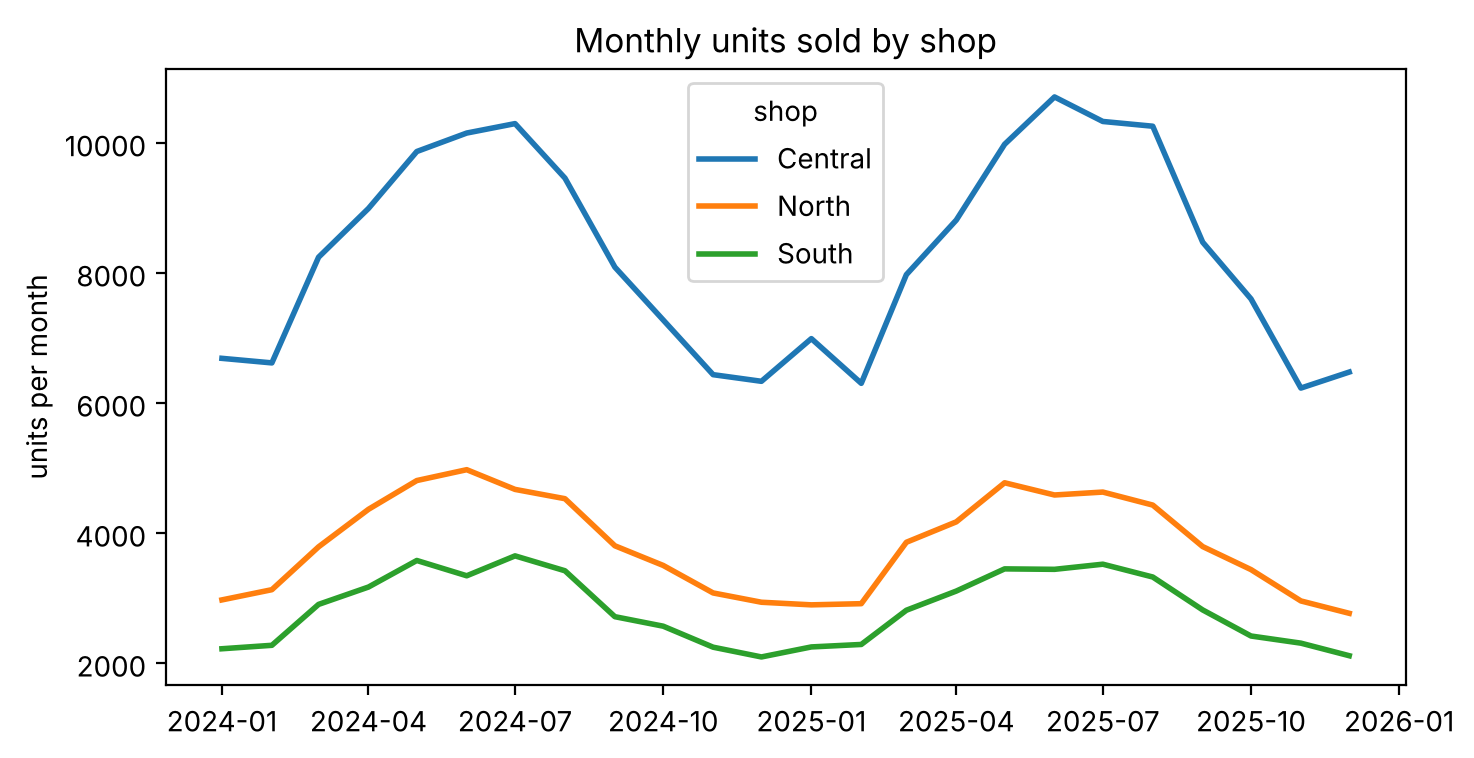

In [3]:
monthly = (sales.assign(month=sales["date"].dt.to_period("M").dt.to_timestamp())
           .groupby(["month", "shop"])["units"].sum().unstack())

fig, ax = plt.subplots(figsize=(8, 4))
for shop in monthly.columns:
    ax.plot(monthly.index, monthly[shop], label=shop, linewidth=2)
ax.set_title("Monthly units sold by shop")
ax.set_ylabel("units per month")
ax.legend(title="shop")
plt.show()

**Reading it:** each line is one shop. Look for the overall trend (here roughly level from 2024 to
2025), repeating patterns (a clear seasonal peak in the middle of each year) and how the shops differ
in level (Central sells about twice as much as North). A line implies continuity, so use it for ordered
x values such as time, not for unrelated categories.

## Bar chart: comparing groups

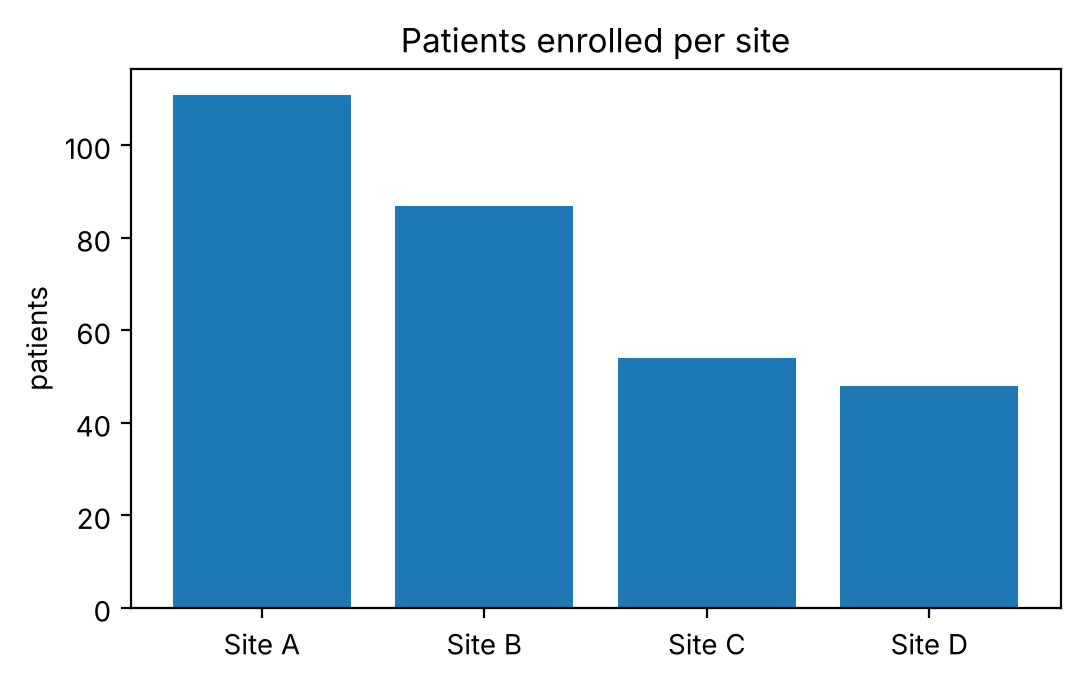

In [4]:
counts = patients["site"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values)
ax.set_title("Patients enrolled per site")
ax.set_ylabel("patients")
plt.show()

Bars must start at zero. For many categories or long names, horizontal bars (`barh`) read better,
sorted by value:

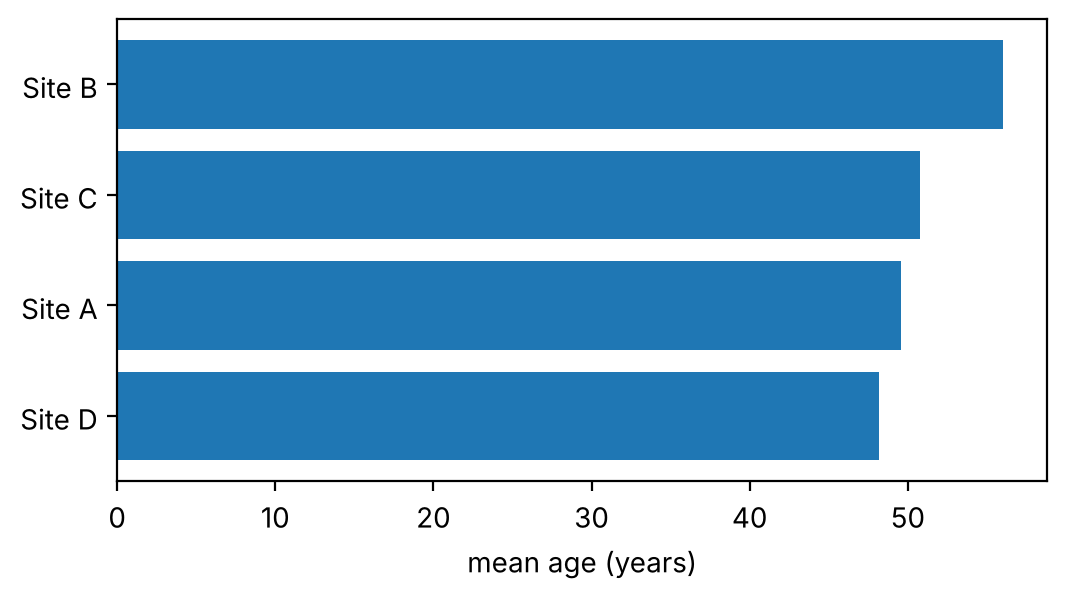

In [5]:
mean_age = patients.groupby("site")["age"].mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(mean_age.index, mean_age.values)
ax.set_xlabel("mean age (years)")
plt.show()

### Grouped bars

Bars for two groups side by side, shifted by half a bar width:

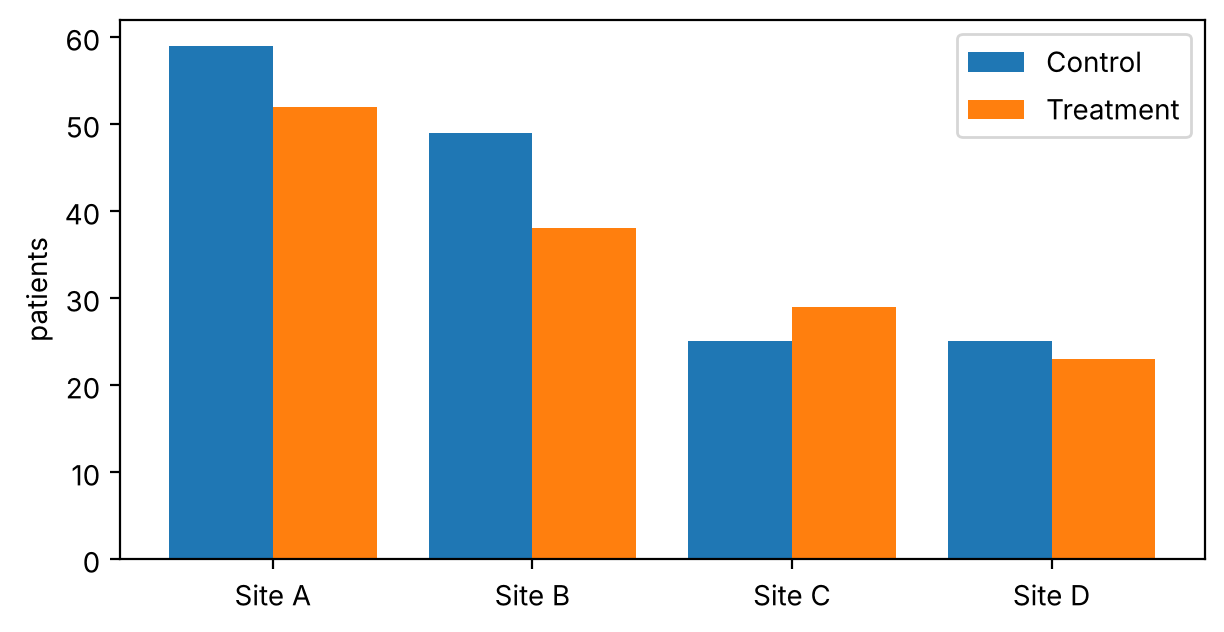

In [6]:
tab = pd.crosstab(patients["site"], patients["group"])
x = np.arange(len(tab))
w = 0.4

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(x - w / 2, tab["Control"], width=w, label="Control")
ax.bar(x + w / 2, tab["Treatment"], width=w, label="Treatment")
ax.set_xticks(x, tab.index)
ax.set_ylabel("patients")
ax.legend()
plt.show()

## Scatter plot: relationships

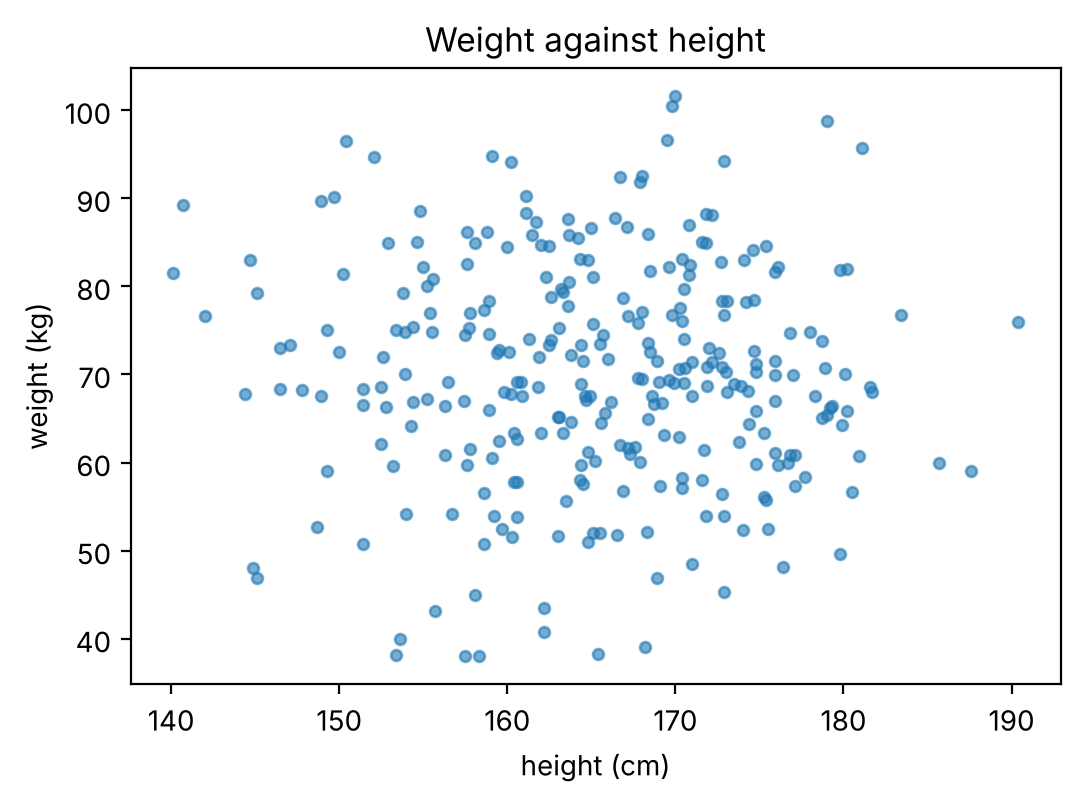

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(patients["height_cm"], patients["weight_kg"], s=15, alpha=0.6)
ax.set_xlabel("height (cm)")
ax.set_ylabel("weight (kg)")
ax.set_title("Weight against height")
plt.show()

**Reading it:** look at the direction (do points rise to the right?), the strength (a tight band or a
loose cloud?), its shape (straight or curved) and any points far from the rest. `alpha` makes points
partly transparent so that overlapping points show as darker areas.

## Histogram: one variable's distribution

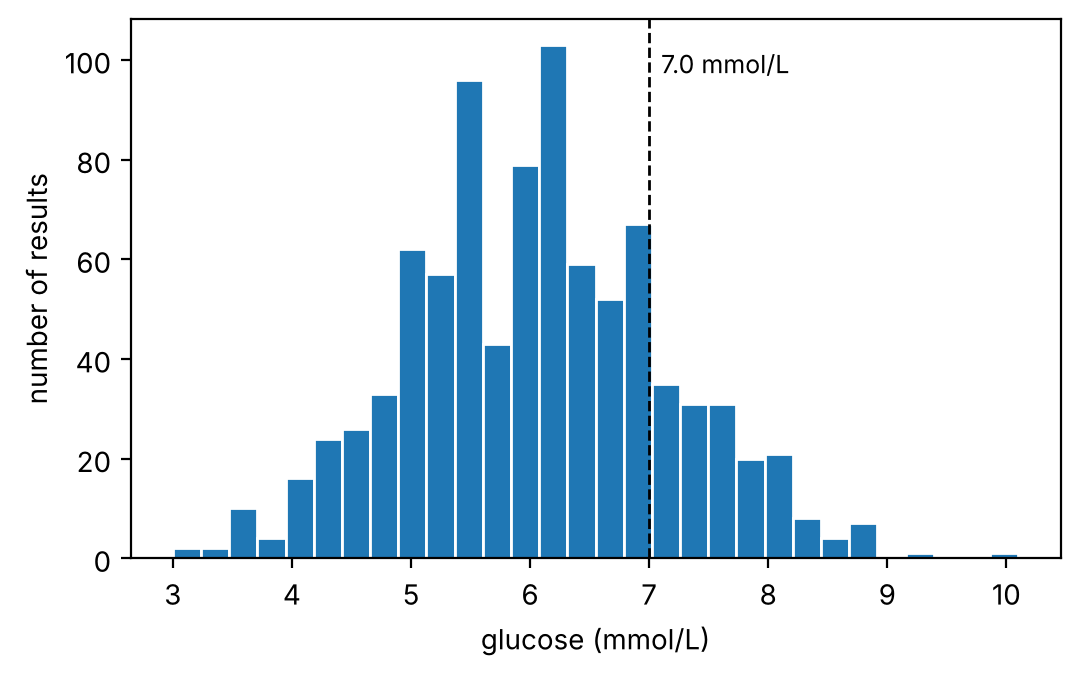

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(labs["glucose_mmol"], bins=30, edgecolor="white")
ax.axvline(7.0, color="black", linestyle="--", linewidth=1)
ax.text(7.1, ax.get_ylim()[1] * 0.9, "7.0 mmol/L", fontsize=9)
ax.set_xlabel("glucose (mmol/L)")
ax.set_ylabel("number of results")
plt.show()

**Reading it:** the height of each bar is how many values fall in that interval. Look for the centre,
the spread, whether one tail is longer (skew), several peaks (mixed groups) and isolated bars
(outliers). The number of bins changes the picture; try a few:

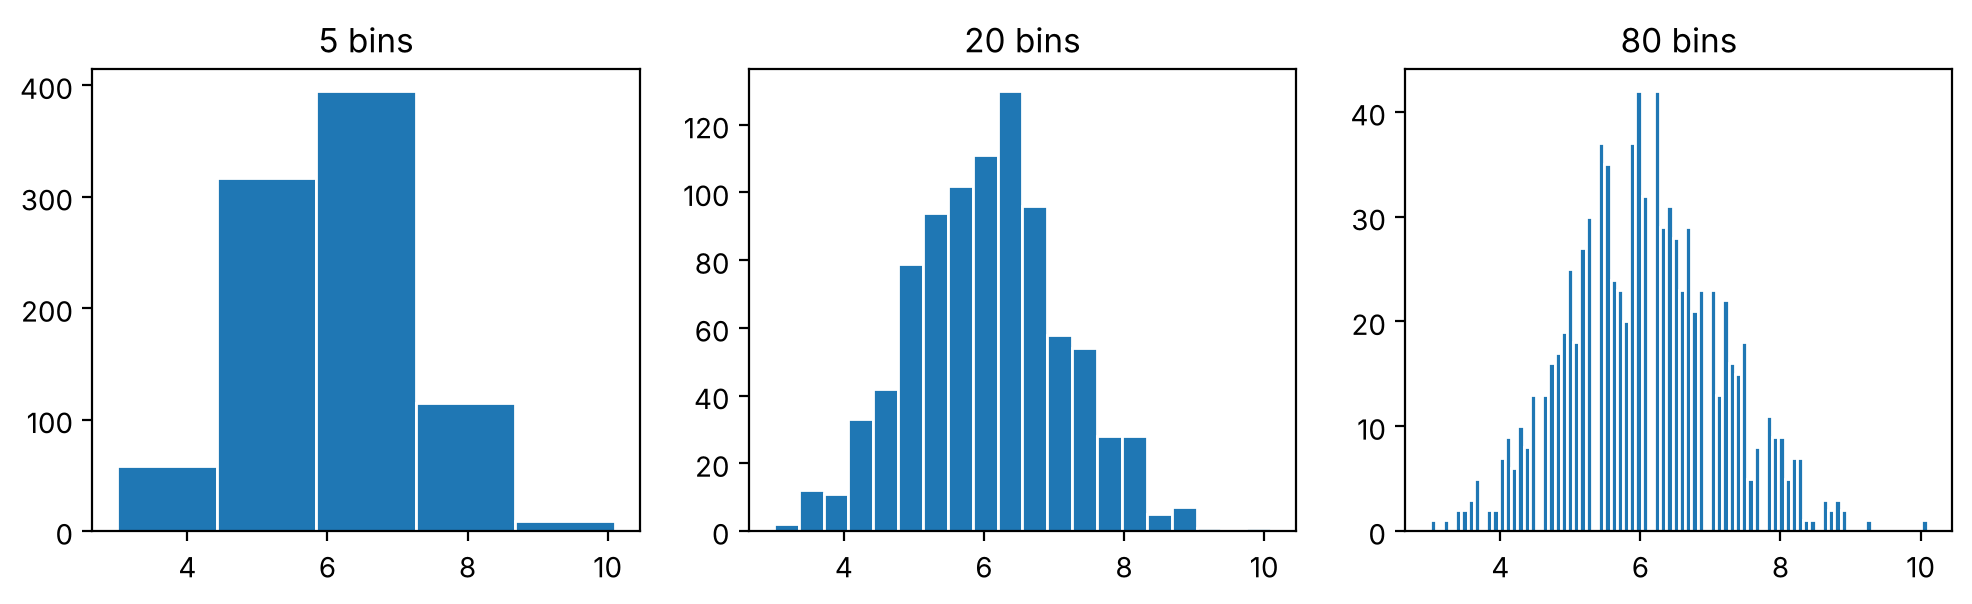

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
for ax, bins in zip(axes, [5, 20, 80]):
    ax.hist(labs["glucose_mmol"], bins=bins, edgecolor="white")
    ax.set_title(f"{bins} bins")
plt.show()

Too few bins hide the shape; too many make it noisy.

## Box plot: comparing distributions

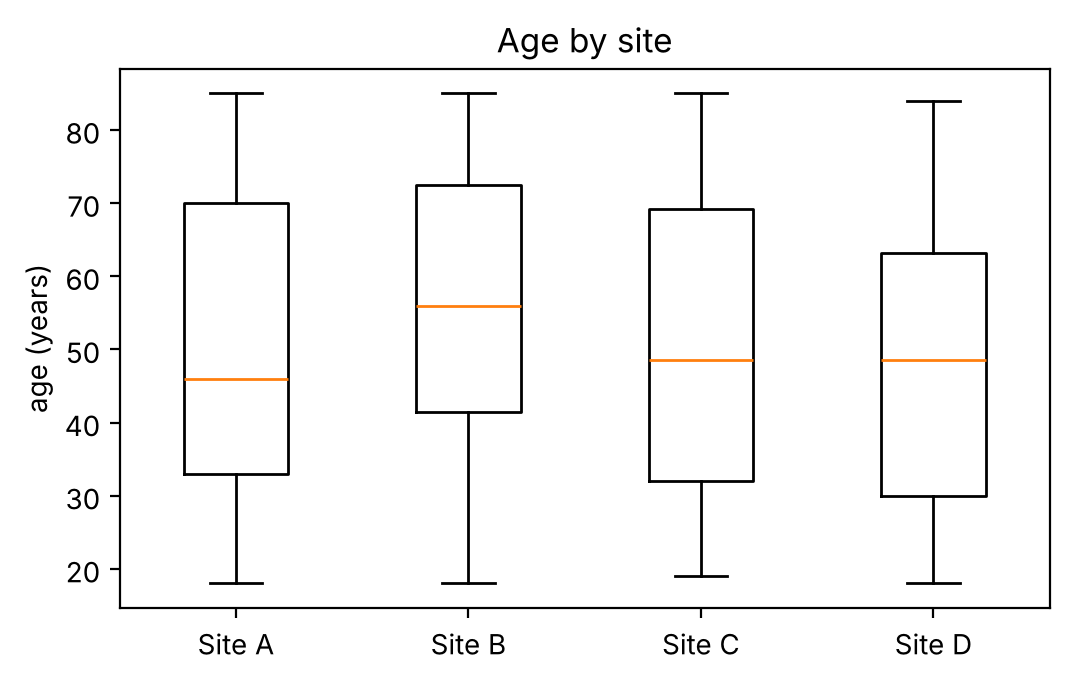

In [10]:
groups = [g["age"].values for _, g in patients.groupby("site")]
labels = sorted(patients["site"].unique())

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot(groups, tick_labels=labels)
ax.set_ylabel("age (years)")
ax.set_title("Age by site")
plt.show()

**Reading a box plot:**

```
   o        ← outlier: beyond 1.5 × IQR from the box
   ┬        ← whisker: furthest value within 1.5 × IQR
 ┌───┐      ← 75th percentile (Q3)
 │───│      ← median
 └───┘      ← 25th percentile (Q1)
   ┴
```

The box holds the middle half of the values. Compare medians (the lines) and spreads (box heights)
across groups.

## Pie chart: parts of a whole

People judge angles poorly, so a bar chart is usually clearer. A pie can work for two or three parts.

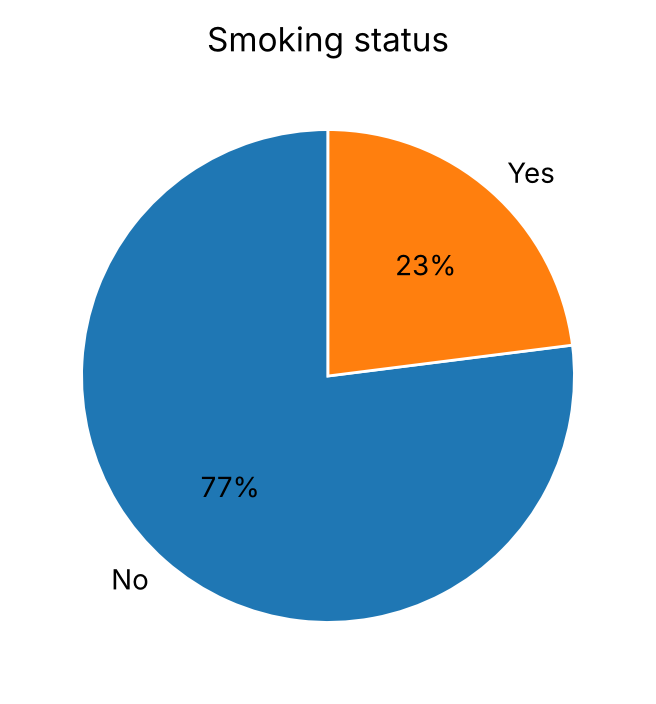

In [11]:
shares = patients["smoker"].value_counts()
fig, ax = plt.subplots(figsize=(4, 4))
ax.pie(shares.values, labels=shares.index, autopct="%1.0f%%", startangle=90,
       wedgeprops={"edgecolor": "white"})
ax.set_title("Smoking status")
plt.show()

## Error bars: means with uncertainty

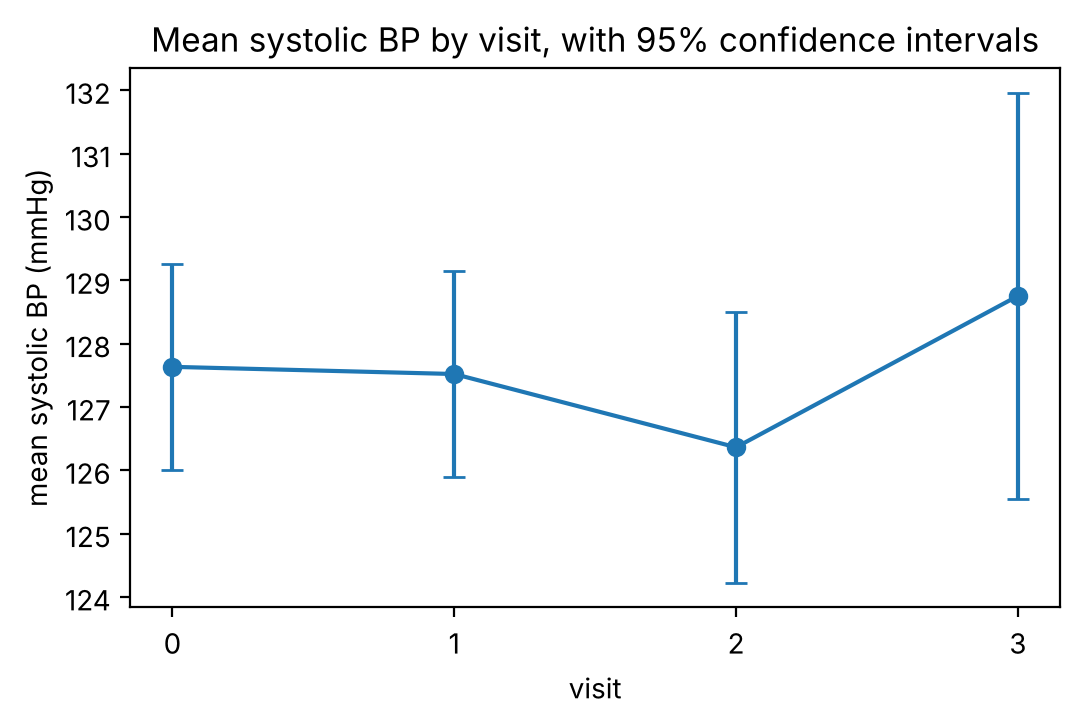

In [12]:
stats = labs.groupby("visit")["systolic_bp"].agg(["mean", "std", "count"])
stats["se"] = stats["std"] / np.sqrt(stats["count"])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(stats.index, stats["mean"], yerr=1.96 * stats["se"], marker="o", capsize=4)
ax.set_xticks(stats.index)
ax.set_xlabel("visit")
ax.set_ylabel("mean systolic BP (mmHg)")
ax.set_title("Mean systolic BP by visit, with 95% confidence intervals")
plt.show()

The bars show ±1.96 standard errors, an approximate 95% confidence interval for each mean. Always say
in the caption what error bars represent: standard deviation, standard error and confidence intervals
look alike but mean different things.

## Practise

Exercises for this folder are in `exercises/Matplotlib_Exercises.ipynb`.

## Further reading

- [Matplotlib user guide](https://matplotlib.org/stable/users/index.html)
- [Plot types gallery](https://matplotlib.org/stable/plot_types/index.html)
- [From data to viz: choosing a chart](https://www.data-to-viz.com/)